In [ ]:
%pip install numpy 
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install plotly

In [114]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

In [92]:
df = pd.read_csv("data.csv")

mete_col = ['Diurnal temperature range (°C)', 'Mean temperature (°C)', 'Mean humidity (%)', 'Solar radiation (MJ/m²)', 'Air pressure (hPa)', 'Dew point temperature (°C)', 'Wind speed (km/h)', 'Mean UV']
flu_col = ["H1", "H3", "B", "AandB"]

In [96]:
# rows without SARS and COVID19 period

tdf = df[~(((df["From"] > "2003-02-21") & (df["From"] < "2003-06-23")) | ((df["From"] > "2020-01-23") & (df["From"] < "2023-03-01")) | (df["From"] < "2004-01-01"))]
tdf


,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV,H1,H3,B,AandB
0,2013,1,2012-12-30,7.01,13.75,66.62,10.95,1020.62,7.12,11.00,2.00,0,23,1,37
1,2013,2,2013-01-06,6.28,14.80,69.04,12.60,1019.42,8.85,11.25,2.29,0,40,6,76
2,2013,3,2013-01-13,7.19,14.98,69.91,13.50,1021.66,9.12,12.25,2.29,0,29,4,75
3,2013,4,2013-01-20,5.98,18.17,79.32,11.48,1019.14,14.35,10.83,2.14,0,37,9,92
4,2013,5,2013-01-27,7.05,17.66,71.69,14.77,1021.33,12.07,13.22,2.67,0,37,6,104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
704,2026,26,2026-06-28,5.87,27.98,88.04,17.43,1008.09,25.65,13.56,3.56,214,476,111,812
705,2026,27,2026-07-05,6.09,28.02,87.32,17.35,1005.17,25.44,11.67,3.86,304,483,123,928
706,2026,28,2026-07-12,4.31,27.47,90.27,12.12,1004.22,25.60,10.67,2.56,383,533,124,1069
707,2026,29,2026-07-19,6.32,28.44,84.48,18.33,1006.11,25.27,9.44,3.81,483,567,138,1217


---

In [6]:
df

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV,H1,H3,B,AandB
0,2013,1,2012-12-30,7.01,13.75,66.62,10.95,1020.62,7.12,11.00,2.00,0,23,1,37
1,2013,2,2013-01-06,6.28,14.80,69.04,12.60,1019.42,8.85,11.25,2.29,0,40,6,76
2,2013,3,2013-01-13,7.19,14.98,69.91,13.50,1021.66,9.12,12.25,2.29,0,29,4,75
3,2013,4,2013-01-20,5.98,18.17,79.32,11.48,1019.14,14.35,10.83,2.14,0,37,9,92
4,2013,5,2013-01-27,7.05,17.66,71.69,14.77,1021.33,12.07,13.22,2.67,0,37,6,104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
704,2026,26,2026-06-28,5.87,27.98,88.04,17.43,1008.09,25.65,13.56,3.56,214,476,111,812
705,2026,27,2026-07-05,6.09,28.02,87.32,17.35,1005.17,25.44,11.67,3.86,304,483,123,928
706,2026,28,2026-07-12,4.31,27.47,90.27,12.12,1004.22,25.60,10.67,2.56,383,533,124,1069
707,2026,29,2026-07-19,6.32,28.44,84.48,18.33,1006.11,25.27,9.44,3.81,483,567,138,1217


In [7]:
df[mete_col].describe()

,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
count,709.000000,709.000000,709.000000,709.000000,709.000000,709.000000,709.000000,709.000000
mean,5.780635,23.182426,79.616178,14.298392,1012.837024,19.089210,12.463836,2.804626
std,1.242457,4.866944,8.708112,4.747681,6.147490,6.034693,2.575496,1.066720
min,2.890000,9.020000,45.900000,3.190000,997.290000,1.540000,6.350000,0.610000
25%,4.930000,18.920000,75.340000,10.920000,1007.840000,14.540000,10.790000,2.000000
50%,5.690000,24.020000,81.620000,14.350000,1012.660000,20.300000,12.250000,2.710000
75%,6.550000,27.730000,85.580000,17.620000,1018.120000,24.770000,13.980000,3.560000
max,9.970000,30.160000,94.550000,26.570000,1026.620000,26.470000,28.230000,6.000000


In [8]:
df[flu_col].describe()

,H1,H3,B,AandB
count,709.000000,709.000000,709.000000,709.000000
mean,105.819464,149.593794,59.245416,321.338505
std,233.296521,283.174331,169.237094,428.734343
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,9.000000,3.000000,36.000000
50%,18.000000,43.000000,13.000000,147.000000
75%,86.000000,169.000000,50.000000,443.000000
max,1999.000000,2560.000000,1978.000000,2741.000000


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 709 entries, 0 to 708
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            709 non-null    int64  
 1   Week                            709 non-null    int64  
 2   From                            709 non-null    object 
 3   Diurnal temperature range (°C)  709 non-null    float64
 4   Mean temperature (°C)           709 non-null    float64
 5   Mean humidity (%)               709 non-null    float64
 6   Solar radiation (MJ/m²)         709 non-null    float64
 7   Air pressure (hPa)              709 non-null    float64
 8   Dew point temperature (°C)      709 non-null    float64
 9   Wind speed (km/h)               709 non-null    float64
 10  Mean UV                         709 non-null    float64
 11  H1                              709 non-null    int64  
 12  H3                              709 

In [56]:
print(f"Number of NA values in each rows: \n{df.isna().sum()}")

Number of NA values in each rows: 
Year                              0
Week                              0
From                              0
Diurnal temperature range (°C)    0
Mean temperature (°C)             0
Mean humidity (%)                 0
Solar radiation (MJ/m²)           0
Air pressure (hPa)                0
Dew point temperature (°C)        0
Wind speed (km/h)                 0
Mean UV                           0
H1                                0
H3                                0
B                                 0
AandB                             0
dtype: int64


In [55]:
print(f"Number of duplicated rows: {df.duplicated().sum()}")

Number of duplicated rows: 0


,H1,H3,B,AandB
Diurnal temperature range (°C),-0.047869,-0.045196,-0.004342,-0.058000
Mean temperature (°C),-0.195900,0.031582,-0.226847,-0.178965
Mean humidity (%),0.015273,0.048860,-0.012050,0.035577
Solar radiation (MJ/m²),-0.176204,0.019005,-0.150073,-0.146465
Air pressure (hPa),0.149961,-0.034672,0.130510,0.112220
Dew point temperature (°C),-0.148125,0.042637,-0.181050,-0.126790
Wind speed (km/h),0.042587,0.021070,-0.005899,0.037059
Mean UV,-0.187497,0.034809,-0.137983,-0.136515


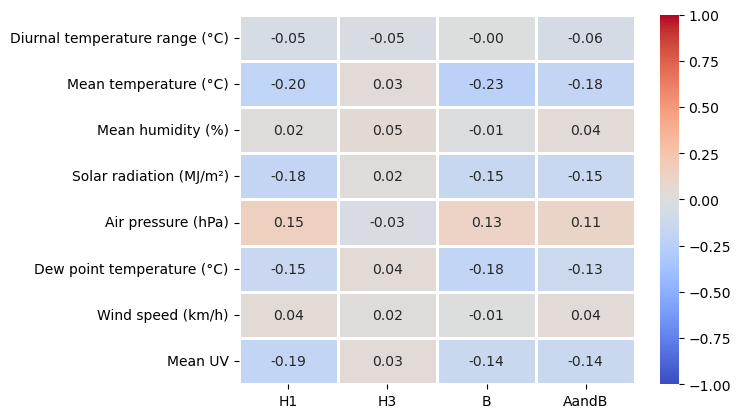

In [91]:
# correlation between meteorlogical factors and influenza detections
corr_df = df.drop(["Year", "Week", "From"], axis=1).corr()
corr_df = corr_df.loc[mete_col, flu_col]
display(corr_df)

sns.heatmap(corr_df, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=1)
plt.show()

,H1,H3,B,AandB
Diurnal temperature range (°C),-0.039810,-0.029968,0.011752,-0.038196
Mean temperature (°C),-0.220063,0.038338,-0.264884,-0.216269
Mean humidity (%),0.018123,0.047337,-0.021513,0.033267
Solar radiation (MJ/m²),-0.176965,0.057863,-0.152199,-0.129472
Air pressure (hPa),0.173694,-0.032651,0.154748,0.145129
Dew point temperature (°C),-0.166263,0.047354,-0.213999,-0.156830
Wind speed (km/h),0.054126,0.036483,0.000028,0.059544
Mean UV,-0.196847,0.067887,-0.144692,-0.129956


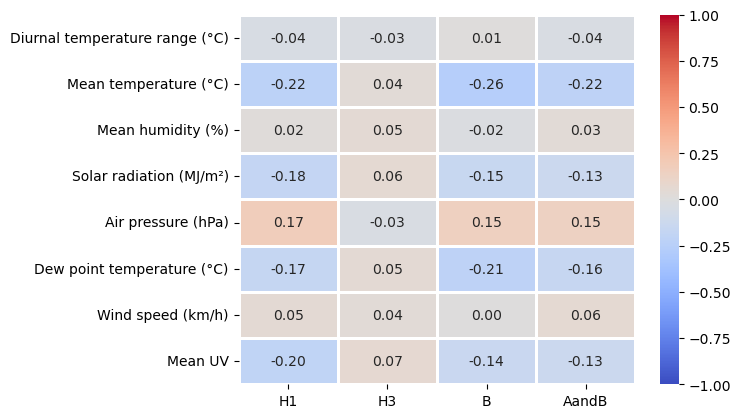

In [95]:
# correlation between meteorlogical factors and influenza detections
corr_df = tdf.drop(["Year", "Week", "From"], axis=1).corr()
corr_df = corr_df.loc[mete_col, flu_col]
display(corr_df)

sns.heatmap(corr_df, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=1)
plt.show()

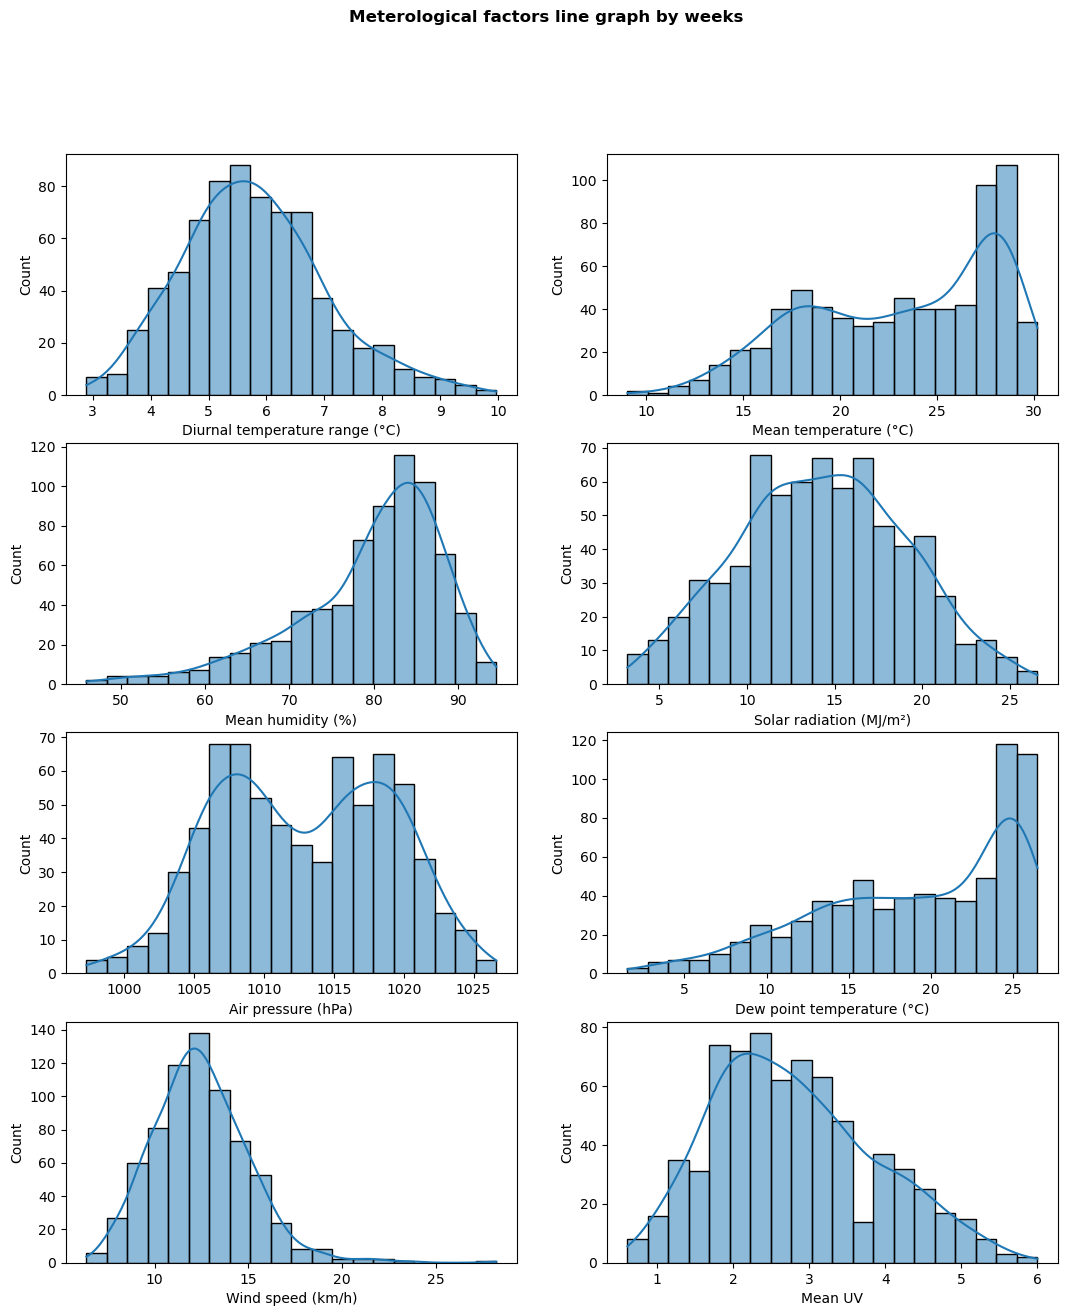

In [80]:
fig, axes = plt.subplots(4, 2, figsize=(6.4*2, 4.8*3))

for i, col in enumerate(mete_col):
    #sns.histplot(data=df, x=col, bins=20, ax=axes[i//2, i%2], kde=True, hue="Year")
    sns.histplot(data=df, x=col, bins=20, ax=axes[i//2, i%2], kde=True)
    axes[i//2, i%2].set_xlabel(col)
    axes[i//2, i%2].set_ylabel("Count")
    
    
plt.suptitle("Meterological factors line graph by weeks", fontweight="bold")
plt.show()
    

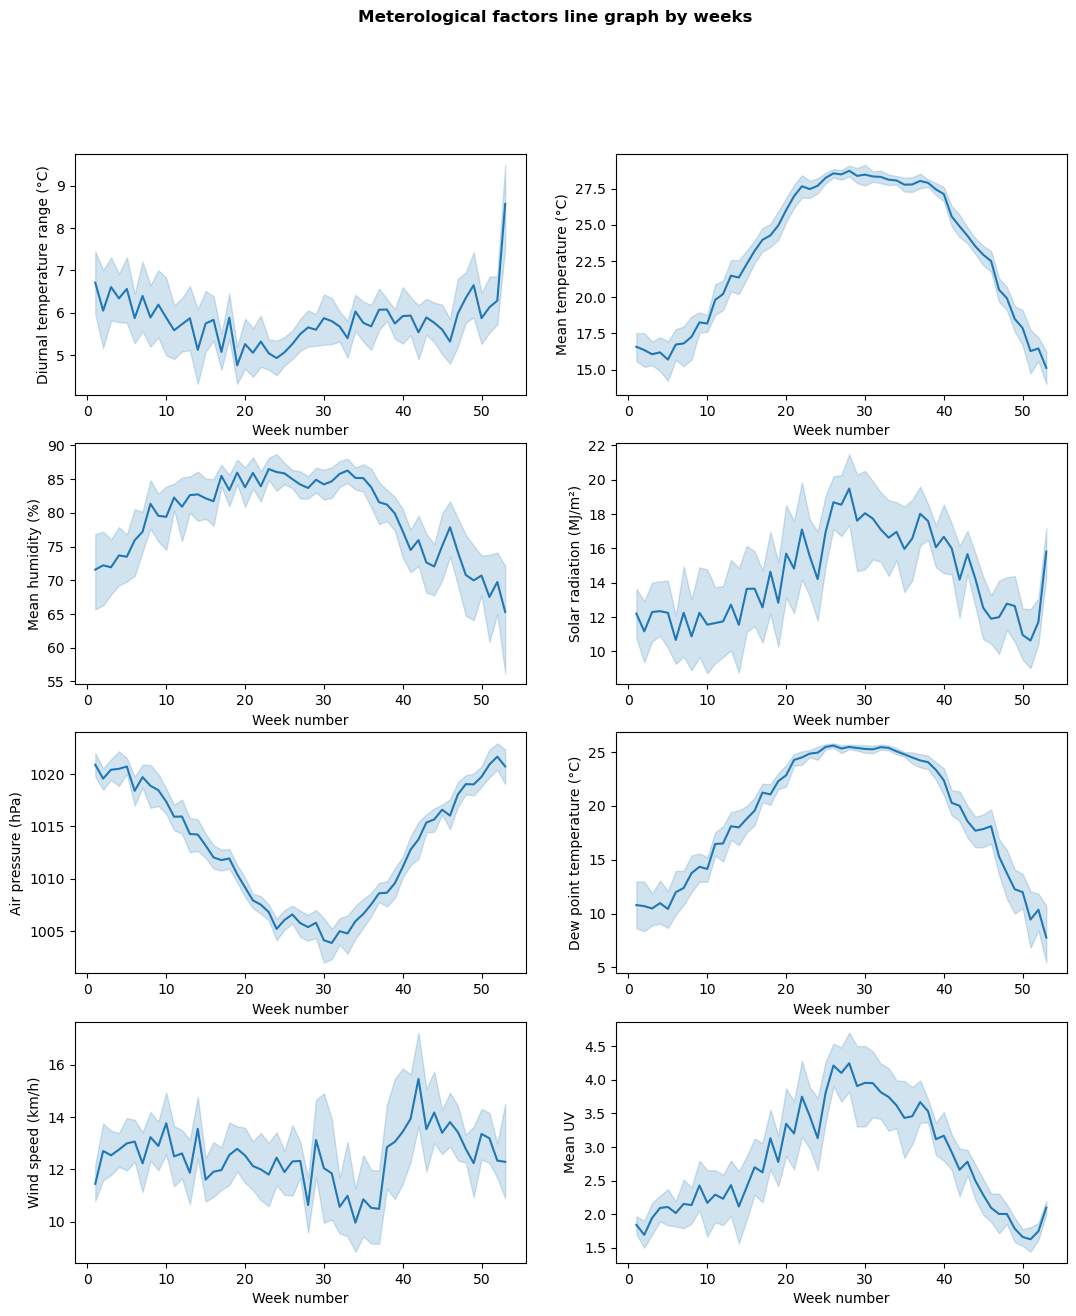

In [115]:
fig, axes = plt.subplots(4, 2, figsize=(6.4*2, 4.8*3))

for i, col in enumerate(mete_col):
    sns.lineplot(x="Week", y=col, data=df, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_xlabel("Week number")
    axes[i//2, i%2].set_ylabel(col)
    
plt.suptitle("Meterological factors line graph by weeks", fontweight="bold")
plt.show()
    

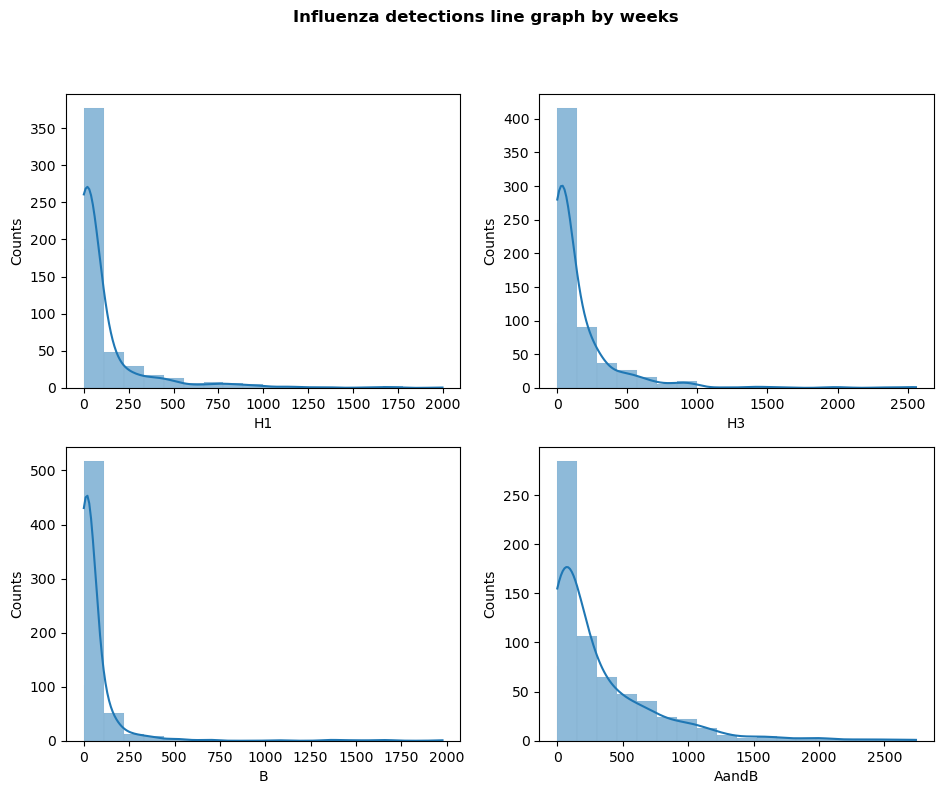

In [77]:
fig, axes = plt.subplots(2, 2, figsize=(6.4*1.75, 4.8*1.75))

for i, col in enumerate(flu_col):
    remaining = np.linspace(1, df[col].max(), 19)
    custom_bins = np.insert(remaining, 0, 0)
    
    sns.histplot(x=col, data=df, ax=axes[i//2, i%2], kde=True, bins=custom_bins)
    axes[i//2, i%2].set_xlabel(col)
    axes[i//2, i%2].set_ylabel("Counts")
    
plt.suptitle("Influenza detections line graph by weeks", fontweight="bold")
plt.show()

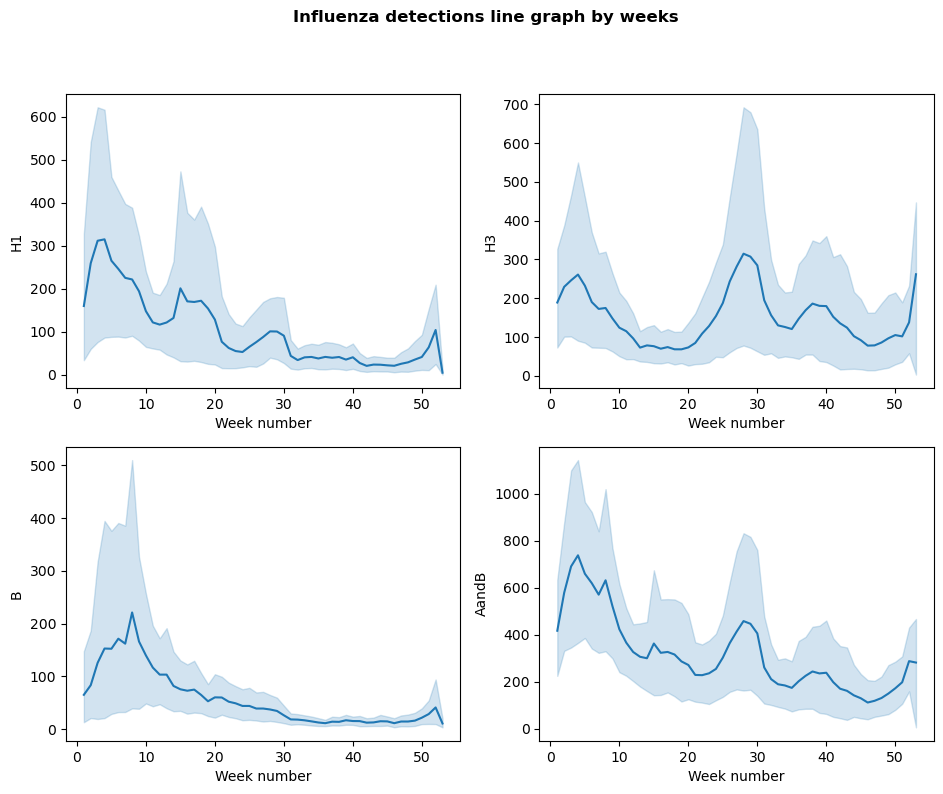

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(6.4*1.75, 4.8*1.75))

for i, col in enumerate(flu_col):
    sns.lineplot(x="Week", y=col, data=df, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_xlabel("Week number")
    axes[i//2, i%2].set_ylabel(col)
    
plt.suptitle("Influenza detections line graph by weeks", fontweight="bold")
plt.show()

,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
Diurnal temperature range (°C),1.000000,-0.184632,-0.678207,0.592658,0.299012,-0.378414,-0.382687,0.298532
Mean temperature (°C),-0.184632,1.000000,0.506151,0.535762,-0.889733,0.955285,-0.213715,0.726022
Mean humidity (%),-0.678207,0.506151,1.000000,-0.231254,-0.612391,0.736987,-0.057284,0.096166
Solar radiation (MJ/m²),0.592658,0.535762,-0.231254,1.000000,-0.331417,0.343800,-0.372026,0.908823
Air pressure (hPa),0.299012,-0.889733,-0.612391,-0.331417,1.000000,-0.900854,0.149890,-0.571197
Dew point temperature (°C),-0.378414,0.955285,0.736987,0.343800,-0.900854,1.000000,-0.182270,0.604391
Wind speed (km/h),-0.382687,-0.213715,-0.057284,-0.372026,0.149890,-0.182270,1.000000,-0.332084
Mean UV,0.298532,0.726022,0.096166,0.908823,-0.571197,0.604391,-0.332084,1.000000


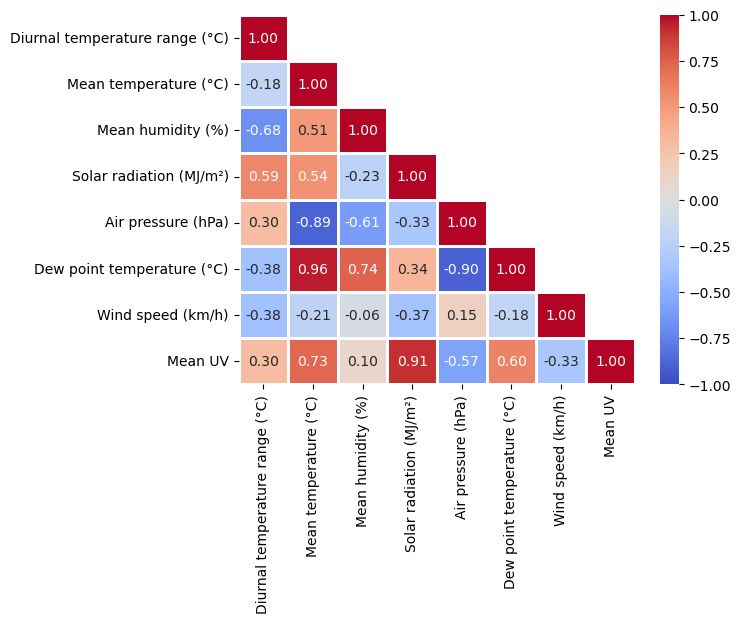

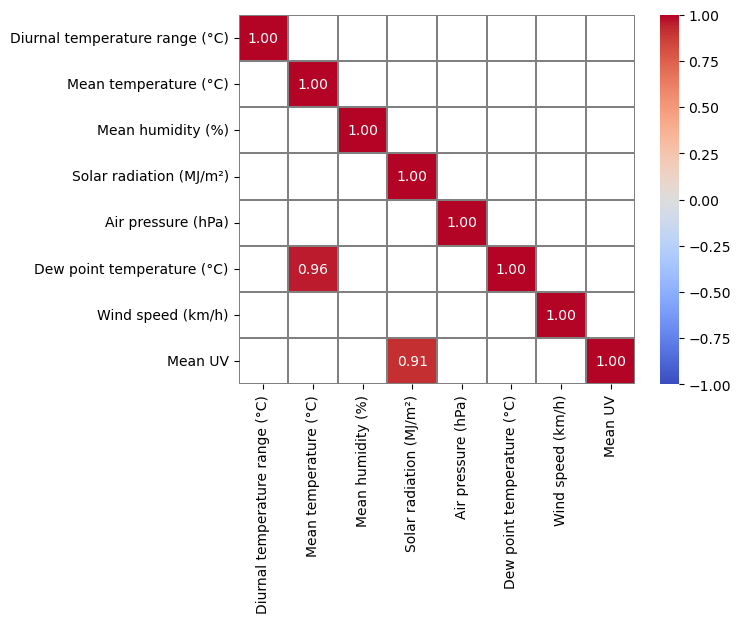

In [21]:
corr_weather = weather_df.drop(["Year", "Week", "From"], axis=1).corr()
display(corr_weather)

for i in range(0, 8):
    for j in range(i+1, 8):
        corr_weather.iloc[i, j] = np.nan

sns.heatmap(corr_weather, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=1)
plt.show()

for i in range(7, 0, -1):
    for j in range(i-1, -1, -1):
            if corr_weather.iloc[i, j] < 0.8:
                corr_weather.iloc[i, j] = np.nan


sns.heatmap(corr_weather, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=0.1, linecolor="gray")
plt.show()


---

In [111]:
tdf = df[~(((df["From"] > "2003-02-21") & (df["From"] < "2003-06-23")) | ((df["From"] > "2020-01-23") & (df["From"] < "2023-03-01")) | (df["From"] < "2004-01-01"))]


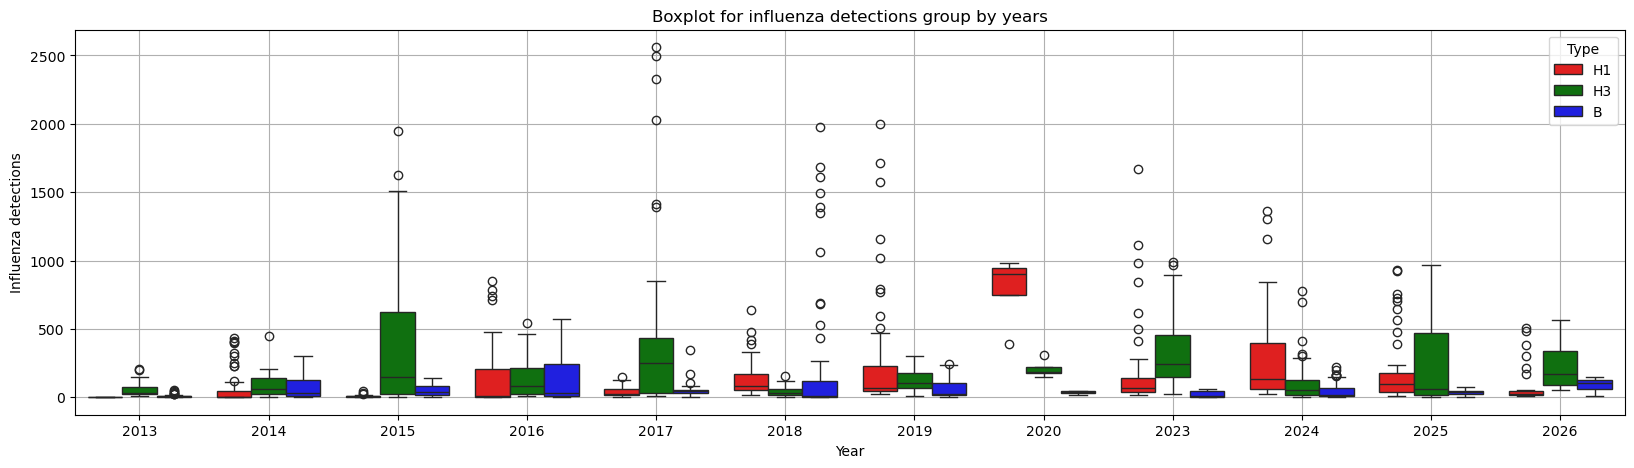

In [97]:
df_long = tdf.melt(
    id_vars=["Year"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

plt.figure(figsize=(20, 5))
sns.boxplot(df_long, x="Year", y="Influenza detections", hue="Type", palette=["red", "green", "blue"])

plt.title("Boxplot for influenza detections group by years")
plt.xlabel("Year")
plt.ylabel("Influenza detections")
plt.grid()
plt.show()

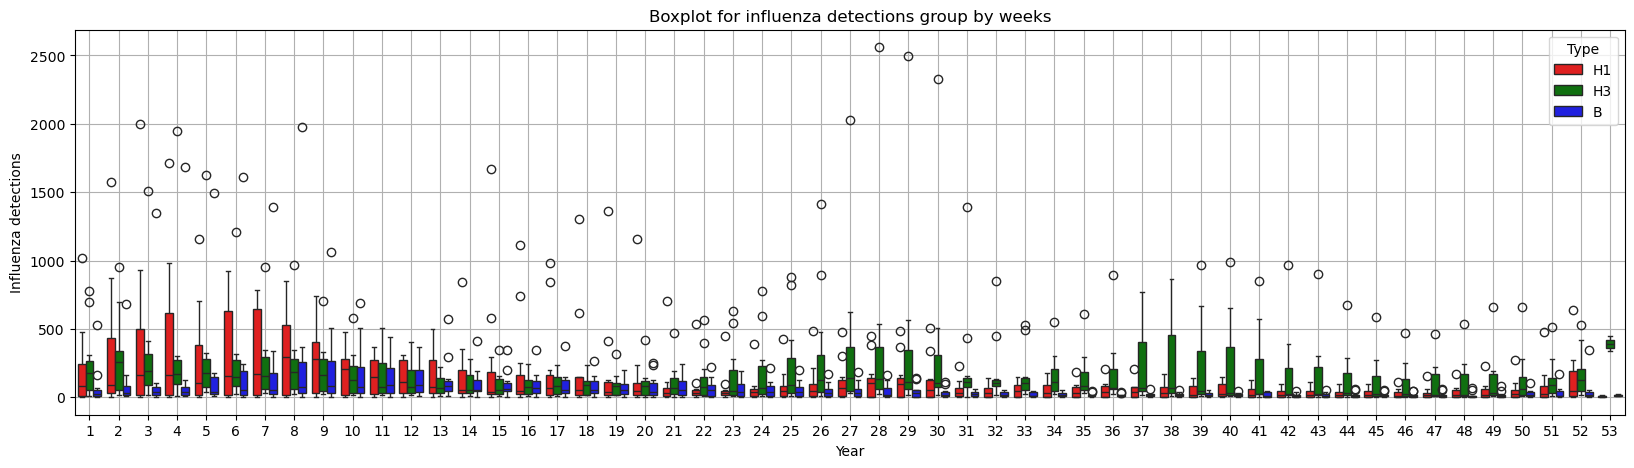

In [98]:
df_long = tdf.melt(
    id_vars=["Week"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

plt.figure(figsize=(20, 5))
sns.boxplot(df_long, x="Week", y="Influenza detections", hue="Type", palette=["red", "green", "blue"])

plt.title("Boxplot for influenza detections group by weeks")
plt.xlabel("Year")
plt.ylabel("Influenza detections")
plt.grid()
plt.show()

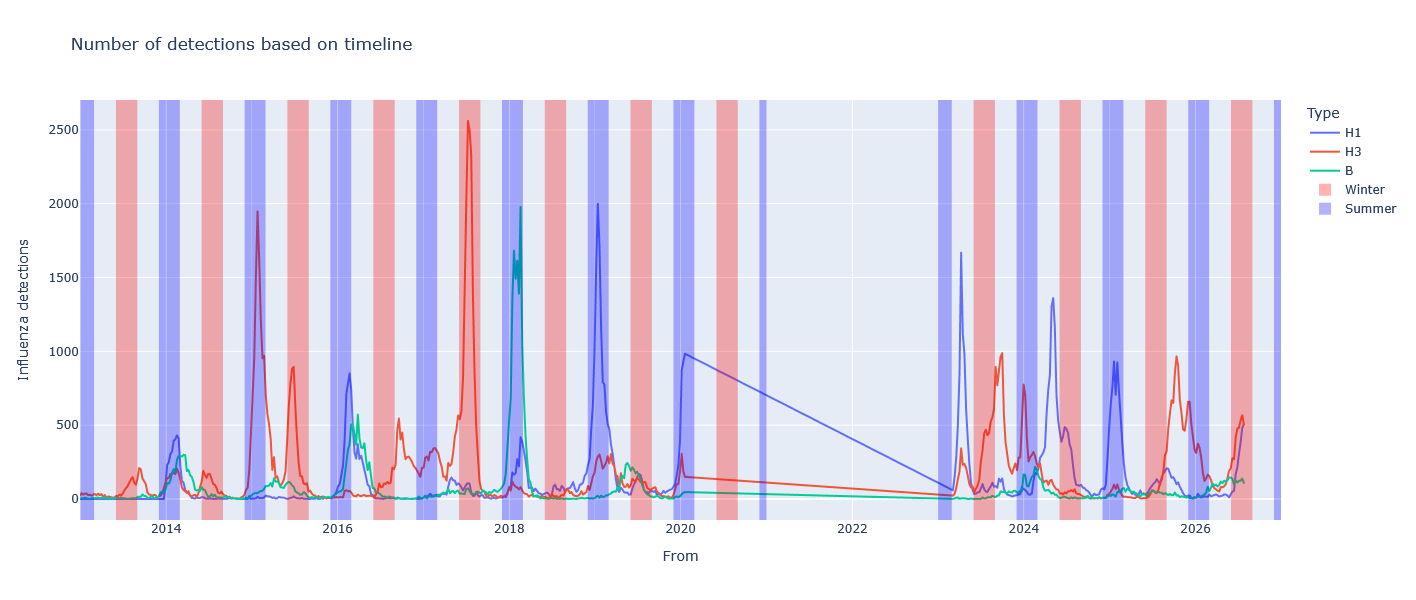

In [110]:
df_long = tdf.melt(
    id_vars=["From"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

fig = px.line(df_long, "From", "Influenza detections", color="Type",
              title="Number of detections based on timeline", 
              width=1500, height=600
             )
for year in sorted(tdf["Year"].unique()):
    start = pd.Timestamp(int(year), 6, 1)
    end = pd.Timestamp(int(year), 8, 31)
    fig.add_vrect(start, end, line_width=0, fillcolor="red", opacity=0.3)
    
    start = pd.Timestamp(int(year), 1, 1)
    end = pd.Timestamp(int(year), 2, 28)
    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

    start = pd.Timestamp(int(year), 12, 1)
    end = pd.Timestamp(int(year), 12, 31)

    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(255, 0, 0, 0.3)"),
        name="Winter", 
        showlegend=True,
    )
)
fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(0, 0, 255, 0.3)"),
        name="Summer", 
        showlegend=True,
    )
)

fig.show()

In [105]:
tdf = df.drop(["Year", "From"], axis=1).groupby("Week").mean()
tdf["Week"] = tdf.index
df_long = tdf.melt(
    id_vars=["Week"],
    value_vars=["H1", "H3", "B", "AandB"],
    var_name="Type",  
    value_name="Number of influenza detections", 
)

fig = px.line(df_long, "Week", "Number of influenza detections", color="Type", 
              title="Number of detections in each week across every year", 
              width=1000, height=500
             )
fig.show()

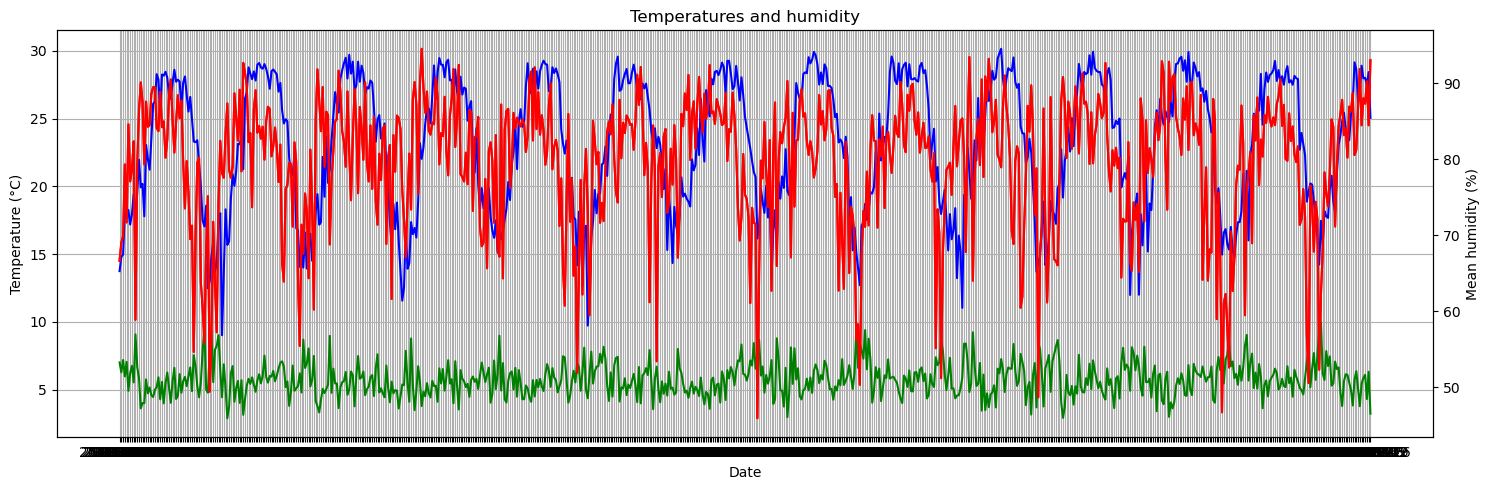

In [106]:
# to-do
fig, ax1 = plt.subplots(figsize=(15, 5))

ax1.plot(df["From"], df["Mean temperature (°C)"], color="blue")
ax1.plot(df["From"], df["Diurnal temperature range (°C)"], color="green")
ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)")

ax2 = ax1.twinx()
line2 = ax2.plot(df["From"], df["Mean humidity (%)"], color="red")
ax2.plot(df["From"], df["Mean humidity (%)"], color="red")
ax2.set_ylabel("Mean humidity (%)")

ax1.grid()
'''
legend_elements = [
    Line2D(), 
    Line2D()
]
ax1.legend(handle=legend_elements)
'''

plt.title("Temperatures and humidity")
plt.tight_layout()
plt.show()

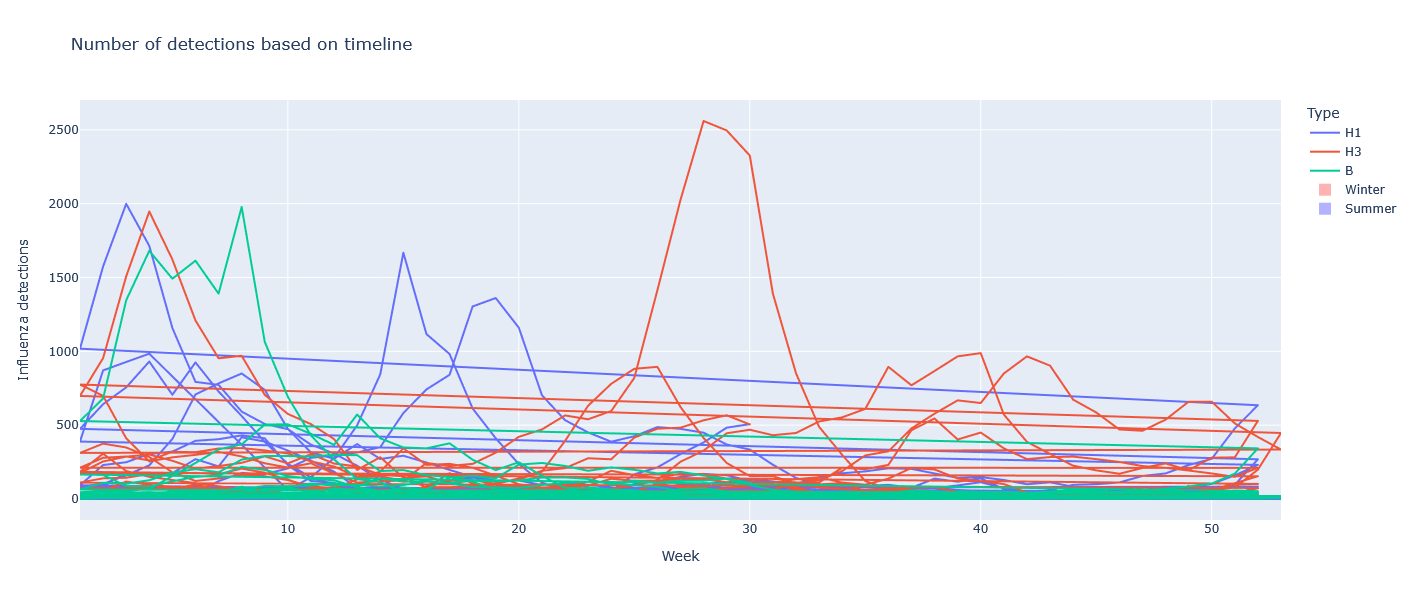

In [112]:
# to-do
df_long = tdf.melt(
    id_vars=["Week"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

fig = px.line(df_long, "Week", "Influenza detections", color="Type",
              title="Number of detections based on timeline", 
              width=1500, height=600
             )
for year in sorted(tdf["Year"].unique()):
    start = pd.Timestamp(int(year), 6, 1)
    end = pd.Timestamp(int(year), 8, 31)
    fig.add_vrect(start, end, line_width=0, fillcolor="red", opacity=0.3)
    
    start = pd.Timestamp(int(year), 1, 1)
    end = pd.Timestamp(int(year), 2, 28)
    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

    start = pd.Timestamp(int(year), 12, 1)
    end = pd.Timestamp(int(year), 12, 31)

    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(255, 0, 0, 0.3)"),
        name="Winter", 
        showlegend=True,
    )
)
fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(0, 0, 255, 0.3)"),
        name="Summer", 
        showlegend=True,
    )
)

fig.show()

ConversionError: Failed to convert value(s) to axis units: [Timestamp('2013-06-01 00:00:00'), Timestamp('2013-08-31 00:00:00')]

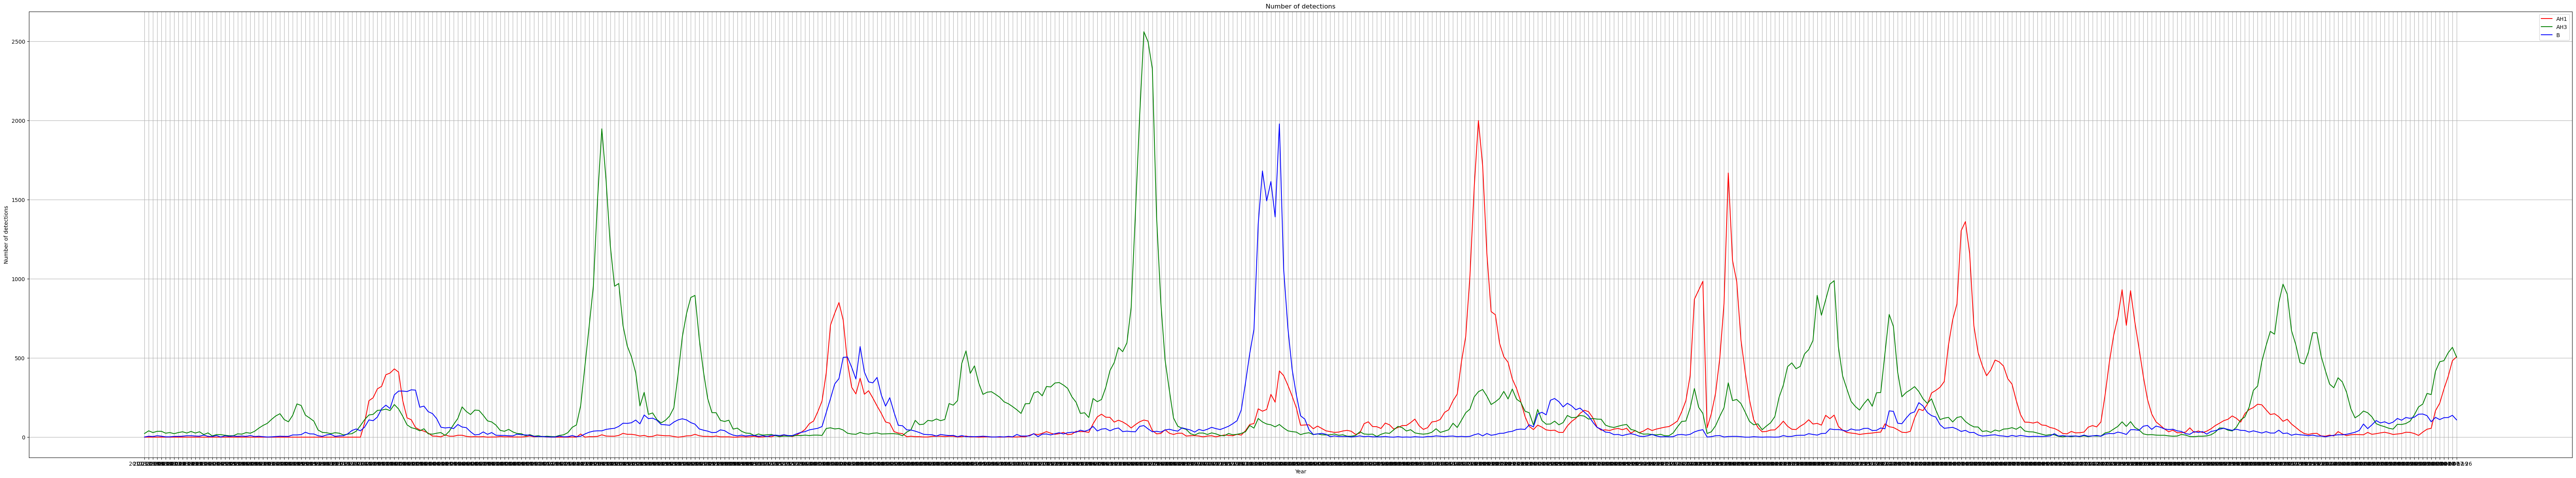

In [113]:
# graph of influenza based on timeline
fig, ax = plt.subplots(figsize=(85, 15))

ax.plot(tdf["From"], tdf["H1"], color="red")
ax.plot(tdf["From"], tdf["H3"], color="green")
ax.plot(tdf["From"], tdf["B"], color="blue")
ax.grid()

ax.set_title("Number of detections")
ax.set_xlabel("Year")
ax.set_ylabel("Number of detections")
ax.legend(["AH1", "AH3", "B"])


for year in sorted(tdf["Year"].unique()): 
    start = pd.Timestamp(int(year), 6, 1)
    end = pd.Timestamp(int(year), 8, 31)
    ax.axvspan(start, end, color="#ffd1dc")

    mid_pt = start + (end - start) / 2
    ax.text(mid_pt, 2000, "Summer", horizontalalignment="center", verticalalignment="center", rotation=90, va="bottom", color="dimgray")

    start = pd.Timestamp(int(year), 1, 1)
    end = pd.Timestamp(int(year), 2, 28)
    ax.axvspan(start, end, color="#ADD8E6")

    mid_pt = start + (end - start) / 2
    ax.text(mid_pt, 2000, "Winter", horizontalalignment="center", verticalalignment="center", rotation=90, va="bottom", color="dimgray")

    start = pd.Timestamp(int(year), 12, 1)
    end = pd.Timestamp(int(year), 12, 31)
    ax.axvspan(start, end, color="#ADD8E6")

plt.show()

---